In [2]:
import duckdb
import pandas as pd
import numpy as np
import csv

import matplotlib.pyplot as plt # install in POWERSHELL using "python -m pip install matplotlib.pyplot"
import seaborn as sns

%matplotlib inline

plt.style.use("ggplot")

con = duckdb.connect("main.duckdb")

In [42]:
# Only run at the end to save.
con.close()

In [ ]:
# Set up, you only need to follow the instructions and run the first time!
# 1. Download the dataset from the census FTP (https://www2.census.gov/programs-surveys/acs/data/pums/2022/5-Year/csv_pus.zip) or try https://www2.census.gov/programs-surveys/acs/data/pums/2022/5-Year/ and navigate to csv_pus.zip
# 2. Unzip the file (may take ~10 minutes for slow computers). Make sure the folder is named "csv_pus" and the files follow the pattern "psam_pusa.csv", "psam_pusb.csv"...
# 3 Place the unzipped folder into the directory
# 4 Run this cell, which make take around 30 minutes or up to an hour on slower computers. Try to keep the computer on and just watch netflix or something on the side :)

  # Not working? You probably don't have python or duckdb installed. Use powershell (or bash if you really want) to verify that python is installed on your machine and then pip install duckdb and pandas. Ask Noam about it or use this link to try and solve it yourself (https://opentechschool.github.io/python-beginners/en/getting_started.html#what-is-python-exactly)

# Combine all the tables into table called "main" (takes ~30mins)
con.sql("""
  CREATE OR REPLACE TABLE main AS
    SELECT * FROM read_csv('csv_pus/psam_pusa.csv')
    UNION
    SELECT * FROM read_csv('csv_pus/psam_pusb.csv')
    UNION  
    SELECT * FROM read_csv('csv_pus/psam_pusc.csv')
    UNION  
    SELECT * FROM read_csv('csv_pus/psam_pusd.csv')
""")

In [9]:
# Function for comparing table sizes and storing it in memory. Useful for seeing if your filter reduced the table to a reasonable size. 
entry_memory = {}

def compare_tables(table1, table2):
    res = con.execute(f"""
    SELECT 
        (SELECT COUNT(*) FROM "{table1}") as count1, 
        (SELECT COUNT(*) FROM "{table2}") as count2
    """).fetchone()
    c1, c2 = res[0], res[1]
    
    entry_memory[table1], entry_memory[table2] = c1, c2
    print(f"{table1}: {c1:,} | {table2}: {c2:,} | Diff: {(c2 - c1):,} ({'more' if c2 - c1 >= 0 else 'less'})")

In [ ]:
# con.sql("""DESCRIBE main """).show(max_rows=999)

# con.sql("""SELECT * FROM main""")

┌─────────┬───────────────┬──────────┬─────────┬─────────┬────────┬────────┬─────────┬─────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬─────────┬───────┬───────┬───────┬───────┬───────┬───────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬──────────┬───────┬───────┬─────────┬─────────┬───────┬───────┬───────┬───────┬────────┬───────┬───────┬───────┬─────────┬───────┬───────┬───────┬─────────┬─────────┬────────┬───────┬─────────┬───────┬───────┬───────┬───────┬───────┬─────────┬─────────┬─────────┬─────────┬───────┬───────────┬───────────┬─────────┬───────┬─────────┬──────────┬───────┬───────┬─────────┬───────┬────────┬────────┬─────────┬────────┬───────────┬───────────┬─────────┬─────────┬────────┬────────┬

Filter

See [data dictionary documentation](https://www2.census.gov/programs-surveys/acs/tech_docs/pums/data_dict/PUMS_Data_Dictionary_2022.pdf) for details

In [3]:
# Get the data dictonary setup so you can easily translate SQL output
with open('PUMS_Data_Dictionary_2018-2022.csv', newline='') as csvfile:
    reader = csv.reader(csvfile, delimiter=",")
    output = list(reader)

# Create data_dict as a resource, then step through the document
data_dict = {}
for row in output:
    # column 1 is always NAME or VAL
    if row[0] == "NAME": 
        # IF NAME, then the second column is the name of the var, the third is the type, and the fifth is a description
        data_dict[row[1]] = {"Desc": row[4], "type": row[2],  "values": {}}
    if row[0] == "VAL":
        # IF VALUE check for type (EITHER N: Numeric, C: Character)
        if row[2] == "N": # if Numeric
            try: 
                value = int(row[5])
            except (ValueError, TypeError):
                value = str(row[5])
            if row[4] == row[5]: # if the min and the max are the same (e.g. range 1 to 1)
                data_dict[row[1]]["values"][value] = row[6]
            # Don't collect data dictionary for anything that has a range that isn't the same. An integer doesn't need a translation.

        else: # if Character
            value = str(row[5])
            data_dict[row[1]]["values"][value] = row[6]


# Function to use in order to translate dataframes or certain columns using the data-dict. (NOT FULLY TESTED!!!)
def translate(target_df, target_column = "*", translate_dict = data_dict):
    return_df = target_df.copy() # copy to avoid breaking anything
    if target_column == "*": # ALL
        xtarget = return_df
    elif isinstance(target_column, str): # string, single column, needs to be put into a list
        target_column = [target_column]
        xtarget = return_df[target_column]
    else: # handle lists
        xtarget = return_df[target_column]

    # loop through target and translate
    for series_name, series in xtarget.items():
        if series_name in translate_dict.keys():
            if translate_dict[series_name]["type"] == "C":
                return_df = return_df.astype({series_name: "str"})            
            
            return_df[series_name] = return_df[series_name].replace(translate_dict[series_name]["values"])
    
    return return_df

# Usage Guide:
    # df: plug in your whole dataframe. NO CHANGES WILL BE MADE TO THIS DATAFRAME.
    # target_column (default = ALL [*]): takes list of column names, single column name, or * (for all) and uses as target for transformation
    # translate_dict (default = data_dict): replacement translation, only for advanced purposes, defaults will work for all required work
    # Returns updated dataframe. 


In [13]:
# GEOGRAPHIC & OTHER FILTER LAYER

# Apply region, division, or state filter as well as any other column filters which go into a new table called "main_refined"
geo = {"type" : "ST", "filter": ["06"]}  #  "REGION" : Region, "DIVISION" : Division, "ST" : State  
alt = {"ESR": "1", "DPHY": "2"}

# Means of transportation to work (JWTRNS): "Bicycle"   
# Employment status recode (ESR):  "Civilian employed, at work"
# Ambulatory Difficulty (DPHY): "No" 

# print([data_dict[geo["type"]]["values"].get(word, f"Not Found ('{word}')") for word in geo["filter"]])

query = f"""
    SELECT * FROM main
    WHERE {geo["type"]} IN {str(geo["filter"])}"""

for key, value in alt.items():
  query += f""" AND {key} = {value!r}"""

print(query)

con.sql("""CREATE OR REPLACE TABLE main_refined AS""" + query)

compare_tables("main", "main_refined")

# print(query)
##### REGION CODE ("REGION")

# 1 Northeast
# 2 Midwest
# 3 South
# 4 West
# 9 Puerto Rico

##### DIVISION CODE ("DIVISION")
# 0 Puerto Rico                              # 1 New England (Northeast region)
# 2 Middle Atlantic (Northeast region)       # 3 East North Central (Midwest region)
# 4 West North Central (Midwest region)      # 5 South Atlantic (South region)
# 6 East South Central (South region)        # 7 West South Central (South Region)
# 8 Mountain (West region)                   # 9 Pacific (West region)


##### STATE CODE ("ST")
# 01 Alabama/AL                 # 21 Kentucky/KY            # 38 North Dakota/ND
# 02 Alaska/AK                  # 22 Louisiana/LA           # 39 Ohio/OH
# 04 Arizona/AZ                 # 23 Maine/ME               # 40 Oklahoma/OK
# 05 Arkansas/AR                # 24 Maryland/MD            # 41 Oregon/OR
# 06 California/CA              # 25 Massachusetts/MA       # 42 Pennsylvania/PA
# 08 Colorado/CO                # 26 Michigan/MI            # 44 Rhode Island/RI
# 09 Connecticut/CT             # 27 Minnesota/MN           # 45 South Carolina/SC
# 10 Delaware/DE                # 28 Mississippi/MS         # 46 South Dakota/SD
# 11 District of Columbia/DC    # 29 Missouri/MO            # 47 Tennessee/TN
# 12 Florida/FL                 # 30 Montana/MT             # 48 Texas/TX
# 13 Georgia/GA                 # 31 Nebraska/NE            # 49 Utah/UT
# 15 Hawaii/HI                  # 32 Nevada/NV              # 50 Vermont/VT
# 16 Idaho/ID                   # 33 New Hampshire/NH       # 51 Virginia/VA
# 17 Illinois/IL                # 34 New Jersey/NJ          # 53 Washington/WA
# 18 Indiana/IN                 # 35 New Mexico/NM          # 54 West Virginia/WV
# 19 Iowa/IA                    # 36 New York/NY            # 55 Wisconsin/WI
# 20 Kansas/KS                  # 37 North Carolina/NC      # 56 Wyoming/WY
#                                                           # 72 Puerto Rico/PR

# Map view of codes: https://www2.census.gov/geo/pdfs/maps-data/maps/reference/us_regdiv.pdf


    SELECT * FROM main
    WHERE ST IN ['06'] AND ESR = '1' AND DPHY = '2'
main: 15,721,123 | main_refined: 816,205 | Diff: -14,904,918 (less)


--- 
### --- Analysis Below --- 
--- 

([<matplotlib.patches.Wedge at 0x1a342f13390>,
 [Text(-1.0997060050800844, 0.025430343898611023, 'No Bike'),
  Text(1.0997060012401967, -0.025430509949597745, 'Bike')])

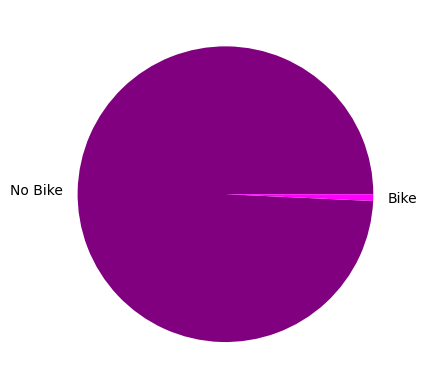

In [18]:

q1 = con.sql("""
SELECT 
	CASE WHEN JWTRNS = '09' THEN 'Bike'
    ELSE 'No Bike' END AS 'BIKE',
	SUM(PWGTP) AS PWGTP
FROM main_refined GROUP BY BIKE
""").df()

q1

fig, ax = plt.subplots()
ax.pie(q1['PWGTP'], labels=q1['BIKE'], colors=["purple", "magenta"])

# plt.xlabel("% of Group who Cycle")
# plt.ylabel(cat_focus + " - " + focus_desc)
# plt.title("Cycling Rates by " + cat_focus)

In [10]:

vehicles = con.sql("""
SELECT JWTRNS, SUM(PWGTP) FROM main 
  GROUP BY JWTRNS
  ORDER BY SUM(PWGTP) DESC""").df()

vehicles = translate(vehicles, "JWTRNS")
vehicles

NameError: name 'translate' is not defined

In [ ]:
con.sql("""
        COPY(
          SELECT AGEP, SUM(CASE WHEN JWTRNS = '09' THEN PWGTP END), SUM(PWGTP) 
          FROM main 
          GROUP BY AGEP 
          ORDER BY AGEP
        ) TO 'output.csv' (HEADER, DELIMITER ',')
        """)

In [ ]:
t1 = con.sql("""
SELECT 
  SUM(PWGTP), COW, JWMNP, JWTRNS, MAR, SCHL, SEX, AVG(WAGP), WKHP, DIS, FOD1P, POWSP, RAC1P 
FROM main_refined G
GROUP BY COW, JWMNP, JWTRNS, MAR, SCHL, SEX, WKHP, DIS, FOD1P, POWSP, RAC1P
""").df()

t1 = translate(t1)
t1


# t1.to_csv("output.csv", index = False)
# 816,205 (NO GROUP)

# 815,085 (ALL GROUP) 
# 798,252 (ALL GROUP, SUM WEIGHT)

# 804,020 (Average WAGP)
# 679,945 (Average WAGP, SUM WEIGHT)
# 677,088 (Average WAGP, No FOD2P, SUM WEIGHT)
# 414,214 (Average WAGP, NO FOD2P or AGEP, SUM WEIGHT)


,sum(PWGTP),COW,JWMNP,JWTRNS,MAR,SCHL,SEX,avg(WAGP),WKHP,DIS,FOD1P,POWSP,RAC1P
0,24.0,Employee of a private for-profit company or bu...,45,Bicycle,Married,"Some college, but less than 1 year",Female,9400.000000,25,Without a disability,NaN,California/CA,Two or More Races
1,138.0,Employee of a private for-profit company or bu...,75,"Car, truck, or van",Married,Master's degree,Female,55250.000000,40,Without a disability,Communications,California/CA,Asian alone
2,12277.0,Employee of a private for-profit company or bu...,30,"Car, truck, or van",Never married or under 15 years old,Regular high school diploma,Female,33912.093023,40,Without a disability,NaN,California/CA,White alone
3,19.0,Employee of a private for-profit company or bu...,<NA>,Worked from home,Never married or under 15 years old,Regular high school diploma,Male,10000.000000,9,Without a disability,NaN,California/CA,Asian alone
4,62.0,Employee of a private for-profit company or bu...,<NA>,Worked from home,Married,Bachelor's degree,Male,31000.000000,40,With a disability,Environmental Science,California/CA,White alone
...,...,...,...,...,...,...,...,...,...,...,...,...,...
414209,21.0,Employee of a private for-profit company or bu...,20,"Car, truck, or van",Never married or under 15 years old,Bachelor's degree,Female,25000.000000,40,Without a disability,Environmental Engineering,California/CA,White alone
414210,22.0,Employee of a private for-profit company or bu...,45,"Car, truck, or van",Married,Master's degree,Female,40000.000000,36,With a disability,Political Science And Government,California/CA,Asian alone
414211,8.0,"Self-employed in own incorporated business, pr...",20,"Car, truck, or van",Married,Bachelor's degree,Male,35000.000000,30,With a disability,Sociology,California/CA,Two or More Races
414212,15.0,Employee of a private for-profit company or bu...,50,"Car, truck, or van",Never married or under 15 years old,Bachelor's degree,Female,35000.000000,40,Without a disability,Commercial Art And Graphic Design,California/CA,Two or More Races


In [ ]:
# Usage Guide

# t2 is for categorical variables
# t3 is for numerical variables
# t4 is for a combination of both

# numeric_focus (t3 & t4), cat_focus (t2 & t5) | Input the name of a categorical/numerical variable
# focus_filter (t2) | Default = [] | Optional list argument to filter for categorical variables. Use the pre-translated code (e.g. "1" not "Male")
# sort_by_percent (t2) | Default = False | Optional boolean argument to sort the resulting values for categorical variables.
# n_focus_Bins (t3 & t4) | Default = None | Optional int or list argument. As int, acts as the amount of bins to sort values into. As list, acts as the bin widths (e.g. [0, 10, 15] is bins  0-9, 10-14, 15+). Displays the min of the bin on the graph
# outlier_rate (*) | Default = 101 | Optional int argument acting as a rate to cap calulations at. Useful in cases where potential outliers are seen, bike% values will be capped to anything at or under that number.
# fig_size (*) | Default = (12, 6) | Optional tuple to set the width and height of the figure respectively

# - - - - - - - - - - - - - - - - - - - - - - - -
# !t2  Dynamic Graph Testing - Categorical
# - - - - - - - - - - - - - - - - - - - - - - - -

# Generate data
def gen_t2(cat_focus, focus_filter = [], fig_size = (12, 6), sort_by_percent=False, outlier_rate = 101):
  focus_desc = data_dict[cat_focus]["Desc"]

  t2 = con.sql(f"""
  SELECT 
    SUM(PWGTP) AS PWGTP, SUM(CASE WHEN JWTRNS = '09' THEN PWGTP END) AS BikeCount, {cat_focus}
  FROM main_refined
  {f""" WHERE {cat_focus} IN {str(focus_filter)}""" if len(focus_filter) > 0 else ""}
  GROUP BY {cat_focus}
  """).df()

  # Translate and process
  t2 = translate(t2)
  # total = t2["PWGTP"].sum()
  t2["bike%"] = (t2["BikeCount"] / t2["PWGTP"]) * 100
  t2 = t2.dropna()
  t2 = t2.query("`bike%` <= @outlier_rate")

  if sort_by_percent:
    t2.sort_values("bike%", ascending=False, inplace=True)

  display(t2)
  
  # Graph
  plt.figure(figsize=fig_size)
  plt.barh(t2[cat_focus], t2["bike%"])
  plt.xlabel("% of Group who Cycle")
  plt.ylabel(cat_focus + " - " + focus_desc)
  plt.title("Cycling Rates by " + cat_focus)



# - - - - - - - - - - - - - - - - - - - - - - - -
# !t3 Dynamic Graph Testing - Numerical
# - - - - - - - - - - - - - - - - - - - - - - - -

def gen_t3(numeric_focus, n_focus_bins = None, fig_size = (12, 6), outlier_rate = 101):
  n_focus_desc = data_dict[numeric_focus]["Desc"]

  
  if isinstance(n_focus_bins, list): 
    # Label the graph with the bin width calulated by the width between the first and second item
    bin_string = f"({abs(n_focus_bins[1]) - abs(n_focus_bins[0])} bin width)"
  elif isinstance(n_focus_bins, int):
    bin_string = f"({str(n_focus_bins)} bins)"
  else:
      bin_string = ""

  # Generate data
  t3 = con.sql(f"""
  SELECT 
    SUM(PWGTP) AS PWGTP, SUM(CASE WHEN JWTRNS = '09' THEN PWGTP END) AS BikeCount, {numeric_focus}
  FROM main_refined
  GROUP BY {numeric_focus}
  """).df()

  # Translate and process
  t3 = translate(t3)
  t3 = t3[pd.to_numeric(t3[numeric_focus], errors='coerce').notnull()] # Check for non-numeric type and get rid of them. Not the best way to handle, but it'll do for this case

  if n_focus_bins != None:
    # Put into bins
    print("Using bins: " + str(n_focus_bins))
    intervals = pd.cut(t3[numeric_focus], bins=n_focus_bins)
    t3[numeric_focus] = intervals.map(lambda x: int(x.left) if pd.notnull(x) else x)
    t3 = t3.groupby(by=numeric_focus).sum().reset_index()

  t3["bike%"] = (t3["BikeCount"] / t3["PWGTP"]) * 100
  t3 = t3.dropna()
  t3 = t3.query("`bike%` <= @outlier_rate")
  display(t3)

  # Graph  
  plt.figure(figsize=fig_size)
  plt.plot(t3[numeric_focus], t3["bike%"])
  plt.xlabel(numeric_focus + " - " + n_focus_desc + bin_string)
  if isinstance(n_focus_bins, list):
    plt.xticks(n_focus_bins, rotation= 90)
  plt.ylabel("% of Group who Cycle")
  plt.title("Cycling Rates by " + numeric_focus)
  

# - - - - - - - - - - - - - - - - - - - - - - - -
# !t4 Dynamic Graph Testing - Numerical & Categorical
# - - - - - - - - - - - - - - - - - - - - - - - -

def gen_t4(cat_focus, numeric_focus, focus_bins = None, fig_size = (12, 6), outlier_rate = 101):
  t4 = con.sql(f"""
  SELECT 
    SUM(PWGTP) AS PWGTP, SUM(CASE WHEN JWTRNS = '09' THEN PWGTP END) AS BikeCount, {numeric_focus}, {cat_focus}
  FROM main_refined
  GROUP BY {numeric_focus}, {cat_focus}
  """).df()

  if isinstance(focus_bins, list): 
    # Label the graph with the bin width calulated by the width between the first and second item
    bin_string = f"({abs(focus_bins[1]) - abs(focus_bins[0])} bin width)"
  elif isinstance(focus_bins, int):
    bin_string = f"({str(focus_bins)} bins)"
  else:
      bin_string = ""

  t4 = translate(t4)
  t4 = t4[pd.to_numeric(t4[numeric_focus], errors='coerce').notnull()] # Check for non-numeric type and get rid of them. Not the best way to handle, but it'll do for this case

  if focus_bins != None:
    # Put into bins
    print("Using bins: " + str(focus_bins))
    intervals = pd.cut(t4[numeric_focus], bins=focus_bins)
    t4[numeric_focus] = intervals.map(lambda x: int(x.left) if pd.notnull(x) else x)
    t4 = t4.groupby(by=[numeric_focus, cat_focus]).sum().reset_index()

  t4["bike%"] = (t4["BikeCount"] / t4["PWGTP"]) * 100
  t4 = t4.dropna()
  t4 = t4.query("`bike%` <= @outlier_rate")
  display(t4)

  # Find out how many lines we need to plot
  t4_supp = con.sql(f"""SELECT DISTINCT {cat_focus} FROM main_refined""").df()
  t4_supp = translate(t4_supp)
  t4_supp = t4_supp[cat_focus].to_list()

  # Graph  
  plt.figure(figsize=fig_size)
  for label in t4_supp:
    plt.plot(t4.query(f'''{cat_focus} == "{label}"''')[numeric_focus], t4.query(f'''{cat_focus} == "{label}"''')["bike%"], label=label)
  plt.legend()
  plt.xlabel(numeric_focus + bin_string)
  if isinstance(focus_bins, list):
    plt.xticks(focus_bins, rotation= 90)
  plt.ylabel("% of Group who Cycle")
  plt.title(f"Cycling Rates by {numeric_focus} & {cat_focus}")

,PWGTP,BikeCount,COW,bike%
3,728317.0,13382.0,State government employee,1.837387
1,1270091.0,14696.0,"Employee of a private not-for-profit, tax-exem...",1.157082
7,32971.0,241.0,Working without pay in family business or farm,0.730945
0,12062314.0,83861.0,Employee of a private for-profit company or bu...,0.695231
2,1438493.0,9018.0,"Local government employee (city, county, etc.)",0.626906
4,344252.0,2141.0,Federal government employee,0.621928
5,1341380.0,5604.0,Self-employed in own not incorporated business...,0.417779
6,677549.0,2758.0,"Self-employed in own incorporated business, pr...",0.407055


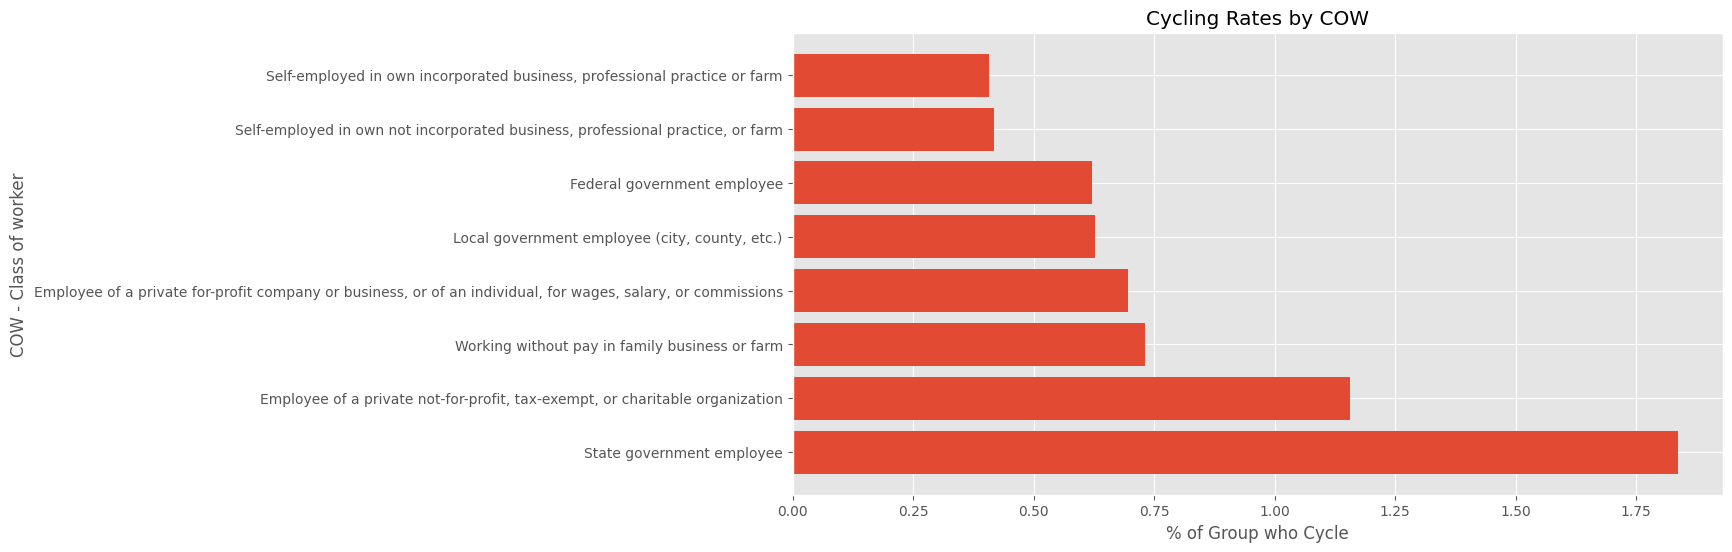

In [125]:
gen_t2("COW", sort_by_percent=True)
# gen_t2("RAC1P", [1, 2, 6, 9], sort_by_percent=True)
# gen_t2("SCHL", ["01", "15", "16", "17", "18", "19", "20", "21", "22", "23", "24"], sort_by_percent=True)
# gen_t2("FOD1P", fig_size=(10, 28), sort_by_percent=True)
# gen_t2("SEX", sort_by_percent=True)
# gen_t2("MAR", sort_by_percent=True)

Using bins: [15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95]


,AGEP,PWGTP,BikeCount,bike%
0,15,782484.0,10277.0,1.313381
1,20,1751985.0,16479.0,0.940590
2,25,2186945.0,21234.0,0.970943
3,30,2178635.0,18149.0,0.833045
4,35,2068954.0,14549.0,0.703206
5,40,1875950.0,10608.0,0.565473
6,45,1885345.0,10540.0,0.559049
7,50,1744651.0,10352.0,0.593356
8,55,1557869.0,9339.0,0.599473
9,60,1066355.0,6105.0,0.572511


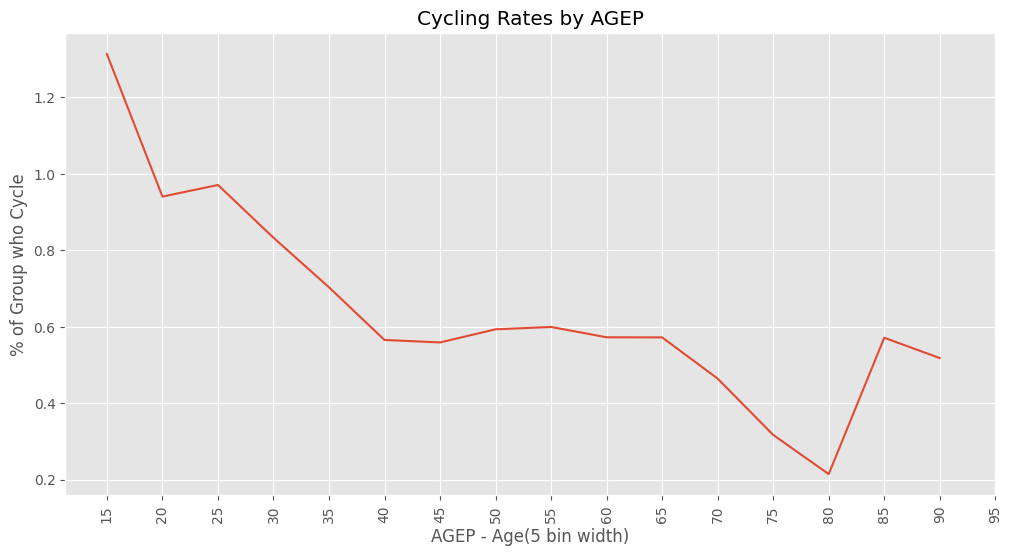

In [134]:
gen_t3("AGEP", list(range(15, 100, 5)))
# gen_t3("WAGP", list(range(0, 675000, 25000)))
# gen_t3("WKHP", list(range(0,101,5)))
# gen_t3("JWMNP", list(range(0, 145, 5)))

Using bins: [15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95]


,AGEP,SEX,PWGTP,BikeCount,bike%
0,15,Female,388370.0,3183.0,0.819579
1,15,Male,394114.0,7094.0,1.799987
2,20,Female,851243.0,6055.0,0.711313
3,20,Male,900742.0,10424.0,1.157268
4,25,Female,1012945.0,6723.0,0.663708
5,25,Male,1174000.0,14511.0,1.236031
6,30,Female,962665.0,4639.0,0.481891
7,30,Male,1215970.0,13510.0,1.111047
8,35,Female,897806.0,3868.0,0.430828
9,35,Male,1171148.0,10681.0,0.912011


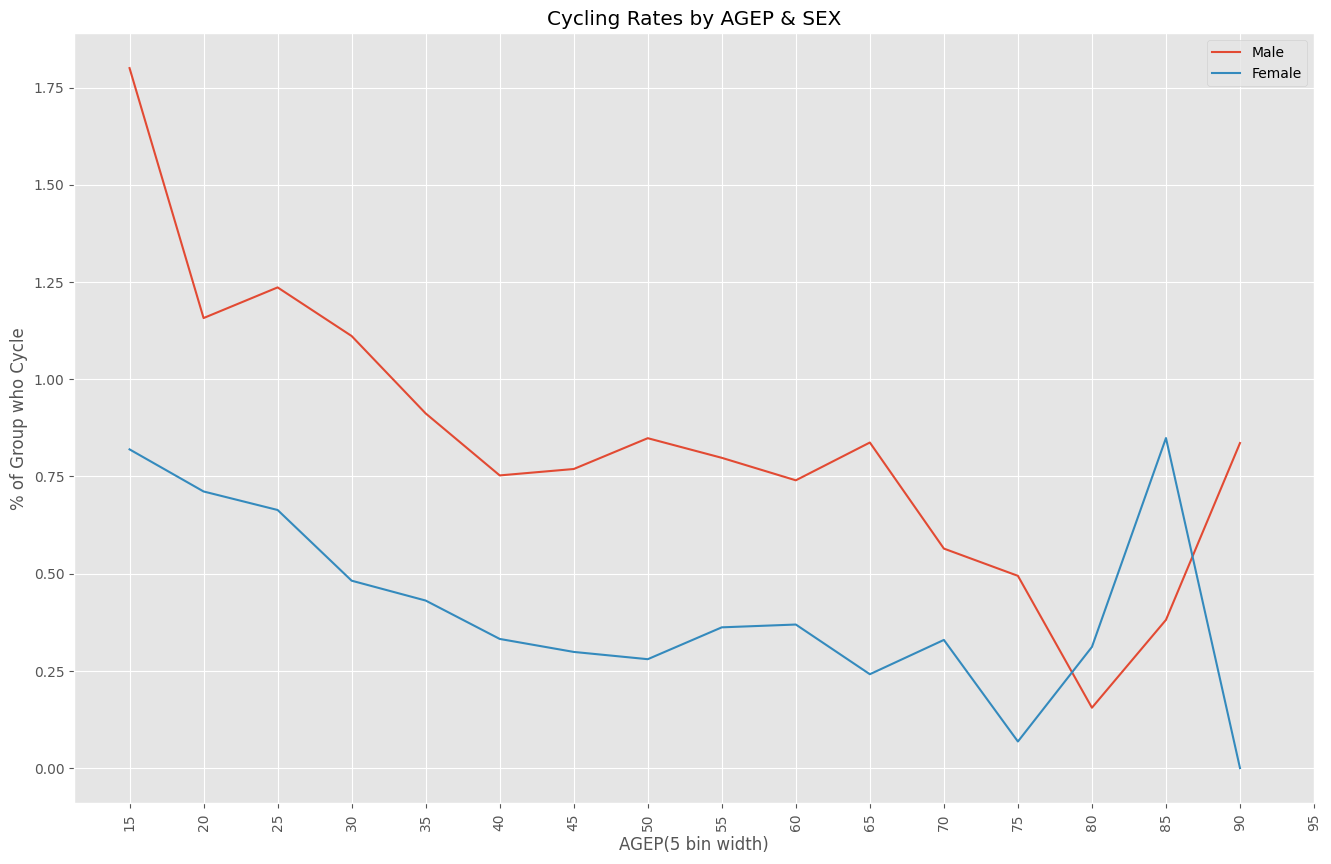

In [142]:
gen_t4("SEX", "AGEP", list(range(15, 100, 5)), fig_size=(16, 10))
# gen_t4("SEX", "WAGP", list(range(0, 675000, 25000)), fig_size=(16, 10))


## Modeling: Predicting Bike Commuting

For this part of the project, I treated the research question as a binary classification problem.

The target variable is whether or not a person uses a bicycle as their main method of transportation to work. In the ACS PUMS data, this comes from `JWTRNS`. I converted this into a binary variable:

- `BIKE = 1` if `JWTRNS == '09'`
- `BIKE = 0` otherwise

The goal is not only to get the best predictive model, but also to understand which variables are most useful for explaining bike commuting behavior. I tested multiple models and multiple feature combinations.

In [170]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight

In [177]:
RANDOM_STATE = 444

# Pull your filtered table into pandas
model_df = con.sql("SELECT * FROM main_refined").df()

# Make sure JWTRNS is treated consistently as a string code
model_df["JWTRNS"] = model_df["JWTRNS"].astype(str).str.zfill(2)

# Target: 1 = bike, 0 = not bike
model_df["BIKE"] = (model_df["JWTRNS"] == "09").astype(int)

print(f"""Rows: {len(model_df)}
Bike commuter rate:
{(model_df.groupby("BIKE")["PWGTP"].sum() / model_df["PWGTP"].sum()).rename("percent")}

Counts:
{model_df.groupby("BIKE")["PWGTP"].sum().rename("count")}
""")

Rows: 816205
Bike commuter rate:
BIKE
0    0.99264
1    0.00736
Name: percent, dtype: float64

Counts:
BIKE
0    17763666
1      131701
Name: count, dtype: int64



In [185]:
# Feature sets to test

core_features = [
    "JWMNP",    # Travel time to work
    "WAGP"      # Wage/salary income
]

demographic_features = [
    "AGEP",     # Age
    "SEX",      # Sex
    "RAC1P",    # Race
    "MAR",      # Marital status
    "SCHL"      # Education
]

employment_features = [
    "COW",      # Class of worker
    "WKHP",     # Weekly hours worked
    "FOD1P"     # Field of degree
]

other_features = [
    "DIS"       # Disability recode
]

feature_sets = {
    "Core only": core_features,
    "Core + demographics": core_features + demographic_features,
    "Core + employment": core_features + employment_features,
    "All selected variables": core_features + demographic_features + employment_features + other_features
}

target = "BIKE"
weight_col = "PWGTP"

for name, features in feature_sets.items():
    print(name, ":", features)

Core only : ['JWMNP', 'WAGP']
Core + demographics : ['JWMNP', 'WAGP', 'AGEP', 'SEX', 'RAC1P', 'MAR', 'SCHL']
Core + employment : ['JWMNP', 'WAGP', 'COW', 'WKHP', 'FOD1P']
All selected variables : ['JWMNP', 'WAGP', 'AGEP', 'SEX', 'RAC1P', 'MAR', 'SCHL', 'COW', 'WKHP', 'FOD1P', 'DIS']


In [178]:
# Use the full filtered dataset for modeling
model_sample = model_df.copy()

print(f"""Using full dataset
Rows: {len(model_sample)}

Counts:
{model_df.groupby("BIKE")["PWGTP"].sum().rename("count")}

Percent:
{(model_df.groupby("BIKE")["PWGTP"].sum() / model_df["PWGTP"].sum()).rename("percent")}
""")

Using full dataset
Rows: 816205

Counts:
BIKE
0    17763666
1      131701
Name: count, dtype: int64

Percent:
BIKE
0    0.99264
1    0.00736
Name: percent, dtype: float64



In [186]:
def make_preprocessor(features):
    numeric_cols = []
    categorical_cols = []
    
    for col in features:
        if data_dict[col]["type"] == "N":
            numeric_cols.append(col)
        else:
            categorical_cols.append(col)
    
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")), # fills missing values
        ("scaler", StandardScaler()) # normalizes
    ])
    
    try:
        categorical_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        categorical_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", categorical_encoder)
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, numeric_cols),
            ("cat", categorical_pipeline, categorical_cols)
        ],
        remainder="drop"
    )
    
    return preprocessor

## Training and Comparing Models

In this step, I trained several different classification models to see which one could best predict whether a person bikes to work.

I tested three models:

- Logistic Regression
- Random Forest
- Gradient Boosting

Each model was tested using different groups of variables. This helps show whether adding more information, such as demographics or employment details, improves the predictions.

The data was split into a training set and a testing set. The model learned from the training set, then was evaluated on the testing set to see how well it performed on new data.

Because bike commuters make up a very small part of the dataset, I used class balancing so the model would not simply predict “not biking” for almost everyone. I also kept the ACS person weights so the results better reflect the population represented by the survey.

The models were compared using accuracy, precision, recall, F1 score, ROC AUC, and average precision. Since bike commuters are rare, F1 score, recall, and average precision are more useful than accuracy alone.

The final output of this cell is a results table that compares each model and feature set. This table helps identify which model performed best and which group of variables was most useful.

In [ ]:
def evaluate_model(model_name, feature_set_name, model, features):
    X = model_sample[features].copy()
    y = model_sample[target].copy()
    weights = model_sample[weight_col].copy()
    
    X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
        X,
        y,
        weights,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=y
    )
    
    preprocessor = make_preprocessor(features)
    
    pipe = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", model)
    ])
    
    # Combines Census person weights with class-balancing weights
    # This helps because bike commuters are rare.
    balanced_weights = compute_sample_weight(class_weight="balanced", y=y_train)
    final_weights = w_train * balanced_weights
    
    pipe.fit(X_train, y_train, model__sample_weight=final_weights)
    
    y_pred = pipe.predict(X_test)
    
    if hasattr(pipe.named_steps["model"], "predict_proba"):
        y_prob = pipe.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_prob, sample_weight=w_test)
        avg_precision = average_precision_score(y_test, y_prob, sample_weight=w_test)
    else:
        y_prob = None
        roc_auc = np.nan
        avg_precision = np.nan
    
    return {
        "Feature Set": feature_set_name,
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred, sample_weight=w_test),
        "Precision": precision_score(y_test, y_pred, sample_weight=w_test, zero_division=0),
        "Recall": recall_score(y_test, y_pred, sample_weight=w_test, zero_division=0),
        "F1": f1_score(y_test, y_pred, sample_weight=w_test, zero_division=0),
        "ROC AUC": roc_auc,
        "Avg Precision": avg_precision,
        "Pipeline": pipe,
        "X_test": X_test,
        "y_test": y_test,
        "w_test": w_test,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "Features": features
    }


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced", # this should help a bit with the data imbalance
        random_state=RANDOM_STATE
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=18,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=5,
        subsample=0.85,
        random_state=RANDOM_STATE
    )
}

all_results = []

for feature_set_name, features in feature_sets.items():
    for model_name, model in models.items():
        print(f"Training {model_name} using {feature_set_name}...")
        result = evaluate_model(model_name, feature_set_name, model, features)
        all_results.append(result)


Training Logistic Regression using Core only...
Training Random Forest using Core only...
Training Gradient Boosting using Core only...
Training Logistic Regression using Core + demographics...
Training Random Forest using Core + demographics...
Training Gradient Boosting using Core + demographics...
Training Logistic Regression using Core + employment...
Training Random Forest using Core + employment...
Training Gradient Boosting using Core + employment...
Training Logistic Regression using All selected variables...
Training Random Forest using All selected variables...
Training Gradient Boosting using All selected variables...


KeyboardInterrupt: 

In [190]:
results_df = pd.DataFrame([
    {k: v for k, v in result.items() if k not in [
        "Pipeline", "X_test", "y_test", "w_test", "y_pred", "y_prob", "Features"
    ]}
    for result in all_results
])

results_df = results_df.sort_values(by="F1", ascending=False)

results_df

,Feature Set,Model,Accuracy,Precision,Recall,F1,ROC AUC,Avg Precision
5,Core + demographics,Gradient Boosting,0.722302,0.016623,0.638023,0.032402,0.745510,0.026406
8,Core + employment,Gradient Boosting,0.747257,0.015821,0.550290,0.030758,0.720671,0.031204
9,All selected variables,Logistic Regression,0.687355,0.015032,0.649373,0.029383,0.729918,0.025152
6,Core + employment,Logistic Regression,0.699176,0.014178,0.587753,0.027688,0.681288,0.019007
3,Core + demographics,Logistic Regression,0.654818,0.013905,0.663177,0.027239,0.717153,0.021479
2,Core only,Gradient Boosting,0.655814,0.012589,0.596994,0.024657,0.654565,0.013114
0,Core only,Logistic Regression,0.458222,0.009607,0.718432,0.018961,0.631913,0.011306
4,Core + demographics,Random Forest,0.067623,0.007588,0.978105,0.015060,0.664325,0.015460
1,Core only,Random Forest,0.133190,0.007433,0.889873,0.014742,0.542419,0.012492
7,Core + employment,Random Forest,0.011094,0.007312,0.999463,0.014517,0.587896,0.013163


In [191]:
best_result = max(all_results, key=lambda x: x["F1"])

print(f"""Best model: {best_result["Model"]}
Best feature set: {best_result["Feature Set"]}

Features used:
{best_result["Features"]}

Classification report:
{classification_report(
    best_result["y_test"],
    best_result["y_pred"],
    sample_weight=best_result["w_test"],
    zero_division=0
)}""")

Best model: Gradient Boosting
Best feature set: Core + demographics

Features used:
['JWMNP', 'WAGP', 'AGEP', 'SEX', 'RAC1P', 'MAR', 'SCHL']

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.72      0.84 3552503.0
           1       0.02      0.64      0.03   26079.0

    accuracy                           0.72 3578582.0
   macro avg       0.51      0.68      0.44 3578582.0
weighted avg       0.99      0.72      0.83 3578582.0



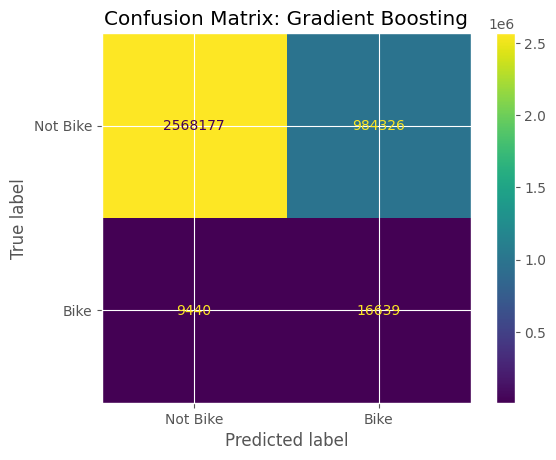

In [192]:
cm = confusion_matrix(
    best_result["y_test"],
    best_result["y_pred"],
    sample_weight=best_result["w_test"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Bike", "Bike"]
)

disp.plot(values_format=".0f")
plt.title(f"Confusion Matrix: {best_result['Model']}")
plt.show()

Final Modeling Summary

I tested multiple classification models to predict whether a person bikes to work. The models tested were Logistic Regression, Random Forest, and Gradient Boosting. Each model was tested with different combinations of variables so I could compare whether adding demographic and employment-related variables improved performance.

The best-performing model was selected using F1 score because bike commuters make up a very small percentage of the dataset. Accuracy alone is not enough for this problem because a model could predict “not bike” for almost everyone and still appear accurate.

After comparing the models, I examined feature importance to understand which variables were most useful. The most important variables give insight into what factors are most associated with biking to work. Variables such as commute time, income, age, education, job type, and other demographic or employment-related factors help explain differences in commuting behavior.

Overall, the modeling results suggest that biking to work is influenced by more than just personal preference. It appears to be connected to commute distance, economic factors, employment characteristics, and demographic patterns.